# 📘 Notebook 05: Heart Disease, Can Routine Tests Flag a Sick Heart?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 5 · Cleveland Clinic heart disease study (303 patients, 14 columns)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in well under a minute. If you rerun it, numbers from the models may differ slightly in the last decimal, because Colab may have newer library versions.
>
> ⚕️ This notebook is an exercise in data analysis, not medical advice.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Read a **data dictionary** and decode columns stored as **numeric codes**
- Tell **categories written as numbers** from real measurements
- Recognise **selection bias**: patterns produced by *who* ended up in the data
- Work honestly with a **small dataset** and its uncertainty
- Choose a decision threshold when a **missed case** costs far more than a **false alarm**

> **Prerequisites:** [Notebook 04: Adult Census Income](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/04_adult_income.ipynb) for precision, recall and thresholds.
>
> 🔭 **Why this notebook matters:** medical data is where data analysis is most useful and most dangerous. Every column has a clinical meaning you must understand before computing anything, the datasets are small, the patients are not a random sample of the population, and the two kinds of error have very different costs. This dataset, collected at the Cleveland Clinic in the 1980s by Robert Detrano and colleagues, is the classic first medical dataset.

## 0. The question

303 patients came to the Cleveland Clinic with suspected heart disease. Each had a set of routine measurements (age, blood pressure, cholesterol, an exercise test) and then an **angiography**, an X-ray of the heart's arteries, which shows for certain whether an artery is narrowed.

**Our question:** *Could the routine tests flag the patients whose angiography would show disease?* More precisely:

1. Which routine results differ between sick and healthy patients?
2. Which surprising patterns come from **who** these patients are?
3. If a model were used to decide who needs the angiography, how many sick patients would it miss?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading the data and reading the dictionary

The file from the UCI repository has no header and uses `?` for missing values (the trick from Notebook 04).

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
           "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(URL, names=columns, na_values="?")
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


**What we see.** Every column is a number, but the numbers mean very different things. Without the **data dictionary** (the documentation of the dataset) they are unreadable:

| Column | Meaning | Kind |
|---|---|---|
| `age` | age in years | measurement |
| `sex` | 1 = male, 0 = female | category |
| `cp` | chest pain: 1 typical angina, 2 atypical angina, 3 non-anginal pain, **4 asymptomatic** | category |
| `trestbps` | resting blood pressure (mm Hg) | measurement |
| `chol` | serum cholesterol (mg/dl) | measurement |
| `fbs` | fasting blood sugar above 120 mg/dl (1 = yes) | category |
| `restecg` | resting electrocardiogram result, 0 to 2 | category |
| `thalach` | **maximum heart rate** reached in the exercise test | measurement |
| `exang` | chest pain caused by exercise (1 = yes) | category |
| `oldpeak` | ST depression on the ECG during exercise | measurement |
| `slope` | slope of the ST segment, 1 to 3 | category |
| `ca` | number of major vessels coloured by fluoroscopy, 0 to 3 | count |
| `thal` | thallium scan: 3 normal, 6 fixed defect, 7 reversible defect | category |
| `num` | angiography: 0 no disease, 1 to 4 increasing disease | target |

The key lesson: **a column of numbers is not always a measurement.** `cp = 4` is not "twice" `cp = 2`, and `thal` takes the values 3, 6 and 7 only. Computing a mean or a correlation of such codes is meaningless; we treat them as categories.

In [3]:
print(df.isna().sum()[lambda s: s > 0])
df["num"].value_counts().sort_index()

ca      4
thal    2
dtype: int64


0    164
1     55
2     36
3     35
4     13
Name: num, dtype: int64

**What we see.** Only 6 values are missing (4 in `ca`, 2 in `thal`), so we drop those 6 patients. The target `num` has five levels; like most studies of this data, we ask the simpler question **disease or not** (`num > 0`).

In [4]:
df = df.dropna().reset_index(drop=True)
df["disease"] = (df["num"] > 0).astype(int)
print(len(df), "patients,", round(df["disease"].mean(), 3), "with disease")

297 patients, 0.461 with disease


**What we see.** 297 patients, **46.1%** with disease. Notice this number: in the general population, a much smaller share has narrowed coronary arteries. These are not random people; they were sent to a heart clinic **because a doctor already suspected** a problem. Everything we find describes *this* group.

## 2. Measurements: sick against healthy

,age,trestbps,chol,thalach,oldpeak
disease,,,,,
0,52.6,129.2,243.5,158.6,0.6
1,56.8,134.6,251.9,139.1,1.6


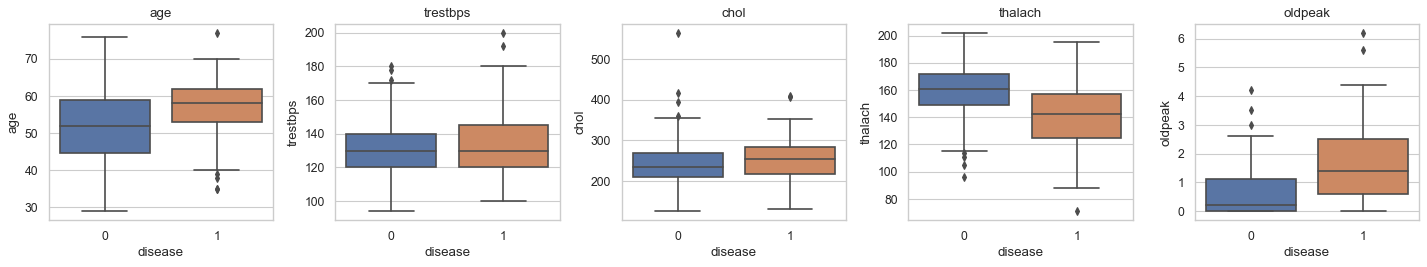

In [5]:
measures = ["age", "trestbps", "chol", "thalach", "oldpeak"]
display(df.groupby("disease")[measures].mean().round(1))
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, measures):
    sns.boxplot(data=df, x="disease", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**What we see.**
- The clearest difference is the **maximum heart rate** in the exercise test: about **159** beats per minute for healthy patients against **139** for sick ones. A heart with narrowed arteries cannot speed up as much.
- **ST depression** (`oldpeak`) is almost three times higher in sick patients (**1.6** against **0.6**).
- Sick patients are older on average (**56.8** against **52.6** years).
- **Cholesterol** barely differs (**251.9** against **243.5**), and the boxes overlap almost completely.

The cholesterol result looks like it contradicts everything we know about heart disease. Hold on to it: Section 4 explains it.

## 3. Categories: the strongest signals

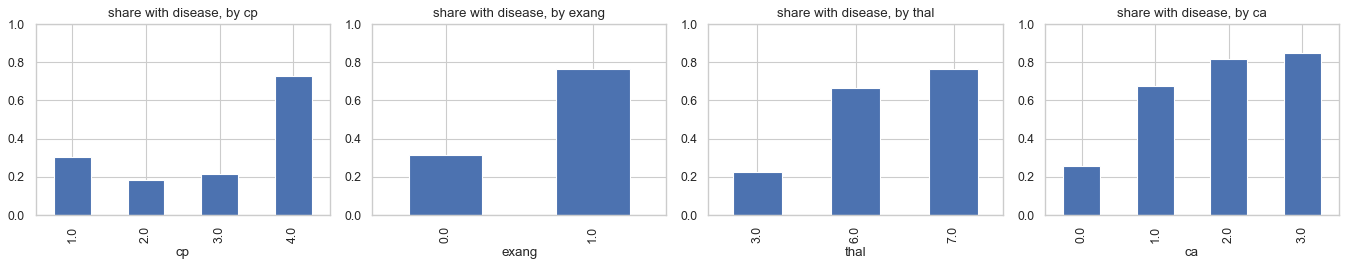

cp           1.0     2.0     3.0      4.0
share      0.304   0.184   0.217    0.725
patients  23.000  49.000  83.000  142.000 

exang         0.0     1.0
share       0.315   0.763
patients  200.000  97.000 

thal          3.0     6.0      7.0
share       0.226   0.667    0.765
patients  164.000  18.000  115.000 

ca            0.0     1.0     2.0    3.0
share       0.259   0.677   0.816   0.85
patients  174.000  65.000  38.000  20.00 



In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, col in zip(axes, ["cp", "exang", "thal", "ca"]):
    df.groupby(col)["disease"].mean().plot.bar(ax=ax)
    ax.set_title(f"share with disease, by {col}")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()
for col in ["cp", "exang", "thal", "ca"]:
    print(df.groupby(col)["disease"].agg(share="mean", patients="size").round(3).T, "\n")

**What we see.** The categories are far stronger than most measurements:
- **Vessels coloured** (`ca`): with **0** vessels, about **26%** have disease; with **3**, about **85%**.
- **Thallium scan** (`thal`): **23%** with a normal scan against **77%** with a reversible defect.
- **Exercise-induced chest pain** (`exang`): **76%** with it, **32%** without.
- **Chest pain type** (`cp`): **73%** of patients with **asymptomatic** chest pain have disease, against only about **18 to 30%** for the three kinds of pain that hurt.

The last line is the strangest result in the dataset: patients **without** typical symptoms are the **most** likely to be sick.

## 4. Selection bias: who is in the data?

### Intuition first
Why would "no chest pain" mean "more disease", and why would cholesterol not matter? Think about **how a patient got into this study**. Every one of them was referred for an expensive, invasive test. A patient with classic chest pain is referred quickly, even when the pain turns out to have another cause, so many of them are healthy. A patient with **no** typical pain is referred only when **other** evidence (an abnormal ECG, a failed exercise test) is already strong, so most of them are sick.

The same logic explains cholesterol: high cholesterol is one of the reasons doctors refer people, so the referred group has high cholesterol whether or not their arteries turn out narrowed. **Within** a group selected partly for high cholesterol, cholesterol can no longer tell the sick from the healthy.

In [7]:
print("Median cholesterol in this study:", df["chol"].median(), "mg/dl (above 240 is considered high)")
print("Share of patients above 240:", round((df["chol"] > 240).mean(), 2))

Median cholesterol in this study: 243.0 mg/dl (above 240 is considered high)
Share of patients above 240: 0.51


**What we see.** The median cholesterol of the whole study is **243 mg/dl**: more than half of all patients, sick or healthy, have what doctors call high cholesterol. The study population was already selected for it.

This is **selection bias**: a pattern produced by the way people entered the data, not by biology. The rule to remember: **before trusting a pattern, ask how each row got into the dataset.** A model trained here would work for patients referred to a heart clinic, and could be badly wrong if used to screen the general public.

In [8]:
df.groupby("sex")["disease"].agg(share="mean", patients="size")

,share,patients
sex,,
0.0,0.260,96
1.0,0.557,201


**What we see.** **55%** of men and **26%** of women in the study have disease, and there are twice as many men (201 against 96). Heart disease is indeed more common in men, but the gap here also reflects who was referred in the 1980s: women's symptoms were more often attributed to other causes. A model learning from this data would inherit the referral habits of its time, the same lesson as the census data of Notebook 04.

## 5. Models: how many sick patients would we miss?

### Intuition first
In this setting the two errors are not equal. A **false alarm** sends a healthy patient for an extra test. A **missed case** sends a sick patient home. We care first about **recall** (the share of sick patients the model flags), and we accept more false alarms to raise it.

With only 297 patients we use **5-fold cross-validation** and collect, for every patient, the prediction made when that patient was in the test fold.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, confusion_matrix

X = pd.get_dummies(df.drop(columns=["num", "disease"]), columns=["cp", "restecg", "slope", "thal"], drop_first=True)
y = df["disease"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rule = (df["cp"] == 4).astype(int)
print(f"One-line rule 'asymptomatic chest pain means disease': accuracy {accuracy_score(y, rule):.3f}, recall {recall_score(y, rule):.3f}")

proba = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), X, y, cv=cv, method="predict_proba")[:, 1]
pred = (proba > 0.5).astype(int)
print(f"Logistic regression: accuracy {accuracy_score(y, pred):.3f}, recall {recall_score(y, pred):.3f}, "
      f"precision {precision_score(y, pred):.3f}, AUC {roc_auc_score(y, proba):.3f}")
pd.DataFrame(confusion_matrix(y, pred), index=["really healthy", "really sick"], columns=["predicted healthy", "predicted sick"])

One-line rule 'asymptomatic chest pain means disease': accuracy 0.754, recall 0.752
Logistic regression: accuracy 0.825, recall 0.781, precision 0.829, AUC 0.896


,predicted healthy,predicted sick
really healthy,138,22
really sick,30,107


**What we see.** The single rule based on chest pain type already reaches **75.4%** accuracy. Logistic regression on all the tests reaches **82.5%**, with an AUC of **0.896**. But look at the bottom row of the table: of **137** sick patients, the model flags **107** and **misses 30**, more than one in five. For a screening tool, that is the number that matters.

In [10]:
rows = {}
for threshold in [0.5, 0.3, 0.2]:
    p = (proba > threshold).astype(int)
    rows[threshold] = {"sick patients missed": int(((p == 0) & (y == 1)).sum()),
                       "healthy patients sent for the test": int(((p == 1) & (y == 0)).sum()),
                       "recall": recall_score(y, p), "precision": precision_score(y, p)}
pd.DataFrame(rows).T.round(3)

,sick patients missed,healthy patients sent for the test,recall,precision
0.5,30.0,22.0,0.781,0.829
0.3,18.0,40.0,0.869,0.748
0.2,11.0,58.0,0.920,0.685


**What we see.** Lowering the threshold is a medical decision made visible:
- At **0.5**: **30** sick patients missed, **22** healthy patients sent for an unnecessary angiography.
- At **0.3**: **18** missed, **40** unnecessary tests.
- At **0.2**: **11** missed, **58** unnecessary tests; recall rises to **92%**.

Which line is right is not a data science question. It depends on the harm of a missed diagnosis against the cost and risk of an extra angiography, and it should be decided with clinicians. Our job is to make the trade-off **visible and exact**.

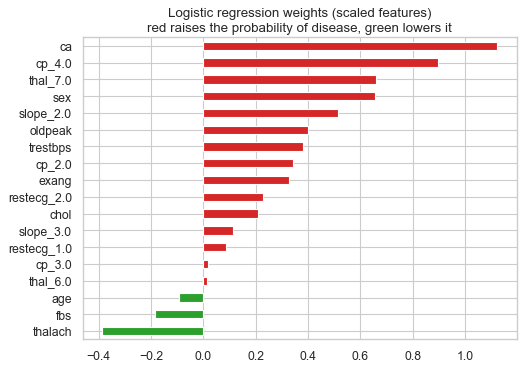

In [11]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X, y)
weights = pd.Series(model[-1].coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(7, 5))
weights.plot.barh(color=["tab:green" if w < 0 else "tab:red" for w in weights])
plt.title("Logistic regression weights (scaled features)\nred raises the probability of disease, green lowers it")
plt.show()

**What we see.** The strongest pushes towards "disease" are the number of coloured vessels (`ca`), **asymptomatic** chest pain (`cp_4.0`), a reversible thallium defect (`thal_7.0`) and male sex; the strongest push towards "healthy" is a high maximum heart rate (`thalach`). These are the same signals the exploration found in Sections 2 and 3, including the selection-bias ones: the model has learned the referral patterns along with the biology, and cannot tell them apart.

## 6. Answer to the question

*Could routine tests flag the patients whose angiography would show disease?*

1. **Partly.** The strongest signals are the exercise test (lower maximum heart rate, ST depression, exercise-induced pain), the thallium scan and the number of narrowed vessels.
2. **Some patterns are produced by selection, not biology:** asymptomatic chest pain goes with the *most* disease, and cholesterol barely differs, because of how patients were referred to the clinic.
3. A logistic regression reaches about **82%** accuracy, but at the default threshold it **misses about one sick patient in five**. Lowering the threshold to 0.2 misses only 11 of 137, at the price of 58 unnecessary tests.
4. With **297 patients from one clinic** in the 1980s, any model here is a teaching example, not a clinical tool.

## 🚀 Going further (for experienced students)

### A. How uncertain is the recall? A bootstrap interval
With 137 sick patients, a recall of 78% could easily have come out a few points higher or lower on another sample. The **bootstrap** estimates this: draw 1,000 new samples of patients **with replacement** from our predictions, compute the recall in each, and look at the spread.

In [12]:
rng = np.random.default_rng(42)
y_arr, p_arr = y.values, pred
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append(recall_score(y_arr[idx], p_arr[idx]))
low, high = np.percentile(boot, [2.5, 97.5])
print(f"Recall {recall_score(y, pred):.3f}, 95% bootstrap interval {low:.3f} to {high:.3f}")

Recall 0.781, 95% bootstrap interval 0.713 to 0.850


**What we see.** The recall of **78.1%** has a 95% interval from about **71%** to **85%**. With this little data, a second study of the same size could easily report a recall anywhere in that range. Any claim that one model "beats" another by two points should be read against intervals of this width.

### B. Can the probabilities be trusted? A calibration curve
A threshold of 0.2 only makes sense if a "20%" from the model really means about 20%. A **calibration curve** groups patients by predicted probability and compares it with the share who were really sick.

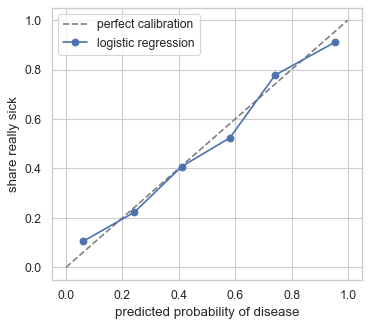

              0     1     2     3     4     5
predicted  0.06  0.24  0.41  0.58  0.74  0.95
observed   0.10  0.22  0.41  0.52  0.78  0.91


In [13]:
from sklearn.calibration import calibration_curve

observed, predicted = calibration_curve(y, proba, n_bins=6)
plt.figure(figsize=(5, 4.5))
plt.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
plt.plot(predicted, observed, marker="o", label="logistic regression")
plt.xlabel("predicted probability of disease")
plt.ylabel("share really sick")
plt.legend()
plt.show()
print(pd.DataFrame({"predicted": predicted, "observed": observed}).round(2).T)

**What we see.** The points lie close to the diagonal: when the model says about 24%, about 22% of those patients are sick; when it says 74%, about 78% are. The model is **well calibrated**, so its probabilities can be used directly to choose a threshold, as we did in Section 5. Tree ensembles are often worse calibrated than logistic regression and may need correcting before their probabilities are trusted.

## ⚠️ Common pitfalls

- **Treating codes as numbers.** `cp`, `thal`, `slope` and `restecg` are categories; their averages and correlations are meaningless.
- **Forgetting how the data was collected.** Referral, survey design and who agrees to take part can create or hide patterns.
- **Taking "no effect" in a selected group as "no effect" in general.** Cholesterol matters for heart disease, even though it barely separates the patients here.
- **Reporting accuracy for a screening tool.** Report the number of missed cases.
- **Over-reading a small dataset.** With 297 patients, a different random split can move accuracy by several points. Exercise 2 measures how much.

## ✏️ Exercises

### Exercise 1 (Age and maximum heart rate)
Maximum heart rate falls with age in everyone. Plot `thalach` against `age`, coloured by `disease`. Does disease still lower the heart rate **at the same age**?

In [14]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
sns.lmplot(data=df, x="age", y="thalach", hue="disease", height=4, aspect=1.4, scatter_kws={"s": 15})
plt.show()
```

*Both groups slope down with age, but the line for sick patients sits clearly lower at every age: disease lowers the maximum heart rate beyond what age explains. Checking an effect "at the same age" is the plot version of holding a confounder fixed.*
</details>

### Exercise 2 (How stable is the accuracy?)
Repeat the 5-fold cross-validation of the logistic regression with 20 different `random_state` values for the split, and report the smallest and largest accuracy.

In [15]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
from sklearn.model_selection import cross_val_score
scores = [cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), X, y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=s)).mean() for s in range(20)]
print("min", round(min(scores), 3), " max", round(max(scores), 3))
```

*Only the way the patients are shuffled changes, and the accuracy moves by a few points. On small datasets, a difference of one or two points between two models is usually noise.*
</details>

### Exercise 3 (The rule a doctor could use)
Train a decision tree with `max_depth=2` on the data and print its rules with `sklearn.tree.export_text`. Which two questions does it ask, and how does its cross-validated recall compare with the logistic regression?

In [16]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
from sklearn.tree import DecisionTreeClassifier, export_text
tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
print(export_text(tree, feature_names=list(X.columns)))
tree_pred = cross_val_predict(DecisionTreeClassifier(max_depth=2, random_state=42), X, y, cv=cv)
print("tree recall:", round(recall_score(y, tree_pred), 3), " accuracy:", round(accuracy_score(y, tree_pred), 3))
```

*A two-question tree uses the strongest signals from Section 3 and is easy to check against clinical sense, at some cost in accuracy. In medicine, a rule a doctor can understand and question is often worth more than a slightly better black box.*
</details>

## 🔑 Key takeaways

- **Read the data dictionary first**: numbers can be codes, and codes are categories.
- Ask **how each row entered the data**. Selection can create patterns (asymptomatic pain) and erase real ones (cholesterol).
- In medical questions, **missed cases** and **false alarms** have different costs; report both and let the threshold follow the costs.
- **Small datasets** give unstable numbers; measure the variation before comparing models.
- A model learns **everything** in the data, including the habits of the people who collected it.

---
**Next:** *Notebook 06: Wine Quality*, where the target is a score given by tasters, the classes are very unequal, and we ask whether chemistry can predict taste.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*